In [31]:
import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype
from plotnine import *
from scipy.stats import *
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.weightstats import ttost_paired, DescrStatsW
from statsmodels.formula.api import logit, mixedlm


# Global Data Pre-processing

In [32]:
mpc  = pd.read_csv('../saved_runs/data/mpc_results_500.csv').drop(columns='delta')
tmpc = pd.read_csv('../saved_runs/data/tmpc_results_500.csv').drop(columns='delta')
sdd = pd.read_csv('../saved_runs/data/sdd_results_500.csv').drop(columns='delta')

joint = pd.merge(mpc.add_suffix('_mpc'), tmpc.add_suffix('_tmpc'), left_on='seed_mpc', right_on='seed_tmpc')
joint = pd.merge(joint, sdd.add_suffix('_sdd'), left_on='seed_mpc', right_on='seed_sdd')

mpc['type'] = 'MPC'
tmpc['type'] = 'TMPC'
sdd['type'] = 'SDD-TMPC'
data = pd.concat([mpc, tmpc, sdd])
data.reset_index(drop=True, inplace=True)
order = CategoricalDtype(
    categories=['MPC', 'TMPC', 'SDD-TMPC'],
    ordered=True
)
data['type'] = data['type'].astype(order)

blank = '#00000000'

# back = '#0C2340'
# lines = '#F0F0F0'
# text = '#FFFFFF'
back = '#FFFFFF'
lines = '#000000'
text = '#000000'


def theme_poster(fig_size: tuple[int, int]): 
    return theme(
        figure_size=fig_size,
        text=element_text(colour=text),
        
        legend_background=element_blank(),
        legend_position='right',
        
        panel_background=element_rect(fill=blank),
        panel_border=element_rect(colour=lines),
        plot_background=element_rect(fill=back, colour=blank),
        strip_background=element_rect(fill=blank, colour=blank),

        axis_ticks_major=element_blank(),
        panel_grid_major=element_line(size=0.4, colour=lines),
        panel_grid_minor=element_line(size=0.2, colour=lines),
    )

# Safety
### Data Handling

In [33]:
collisions = data[['wall_collisions', 'victims_collisions', 'fire_collisions', 'type']]
collisions.columns = ['Terrain', 'Victim', 'Fire', 'type']
collisions = collisions.melt(id_vars='type', value_name='collisions', value_vars=['Terrain', 'Victim', 'Fire'], var_name='collision_type')
collisions['collision_type'] = collisions['collision_type'].astype(CategoricalDtype(
    categories=['Terrain', 'Victim', 'Fire'],
    ordered=True
))

margins = data[['avg_safety_margin', 'type']]
margins.columns = ['Average Safety Margin', 'type']

s_friedman, p_friedman = friedmanchisquare(mpc['fire_collisions'], tmpc['fire_collisions'], sdd['fire_collisions'])
print(s_friedman, p_friedman)

s_wil_mpc_tmpc, p_wil_mpc_tmpc = wilcoxon(mpc['fire_collisions'], tmpc['fire_collisions'])
s_wil_mpc_sdd, p_wil_mpc_sdd  = wilcoxon(mpc['fire_collisions'], sdd['fire_collisions'])
s_wil_tmpc_sdd, p_wil_tmpc_sdd = wilcoxon(tmpc['fire_collisions'], sdd['fire_collisions'])
raw_p_wil = [p_wil_mpc_tmpc, p_wil_mpc_sdd, p_wil_tmpc_sdd]
reject, p_wil_joint, _, _ = multipletests(raw_p_wil, method='bonferroni')
print(reject, p_wil_joint)

s_friedman, p_friedman = friedmanchisquare(mpc['avg_safety_margin'], tmpc['avg_safety_margin'], sdd['avg_safety_margin'])
print(s_friedman, p_friedman)

s_wil_mpc_tmpc, p_wil_mpc_tmpc = wilcoxon(mpc['avg_safety_margin'], tmpc['avg_safety_margin'])
s_wil_mpc_sdd, p_wil_mpc_sdd  = wilcoxon(mpc['avg_safety_margin'], sdd['avg_safety_margin'])
s_wil_tmpc_sdd, p_wil_tmpc_sdd = wilcoxon(tmpc['avg_safety_margin'], sdd['avg_safety_margin'])
raw_p_wil = [p_wil_mpc_tmpc, p_wil_mpc_sdd, p_wil_tmpc_sdd]
reject, p_wil_joint, _, _ = multipletests(raw_p_wil, method='bonferroni')
print(reject, p_wil_joint)

7.399999999991747 0.0247235264704414
[ True False False] [0.02445291 0.3074113  0.32309144]
380.05810397553563 2.9609516816667042e-83
[ True  True  True] [6.80648946e-58 2.92863258e-23 2.65130264e-41]


### Plotting

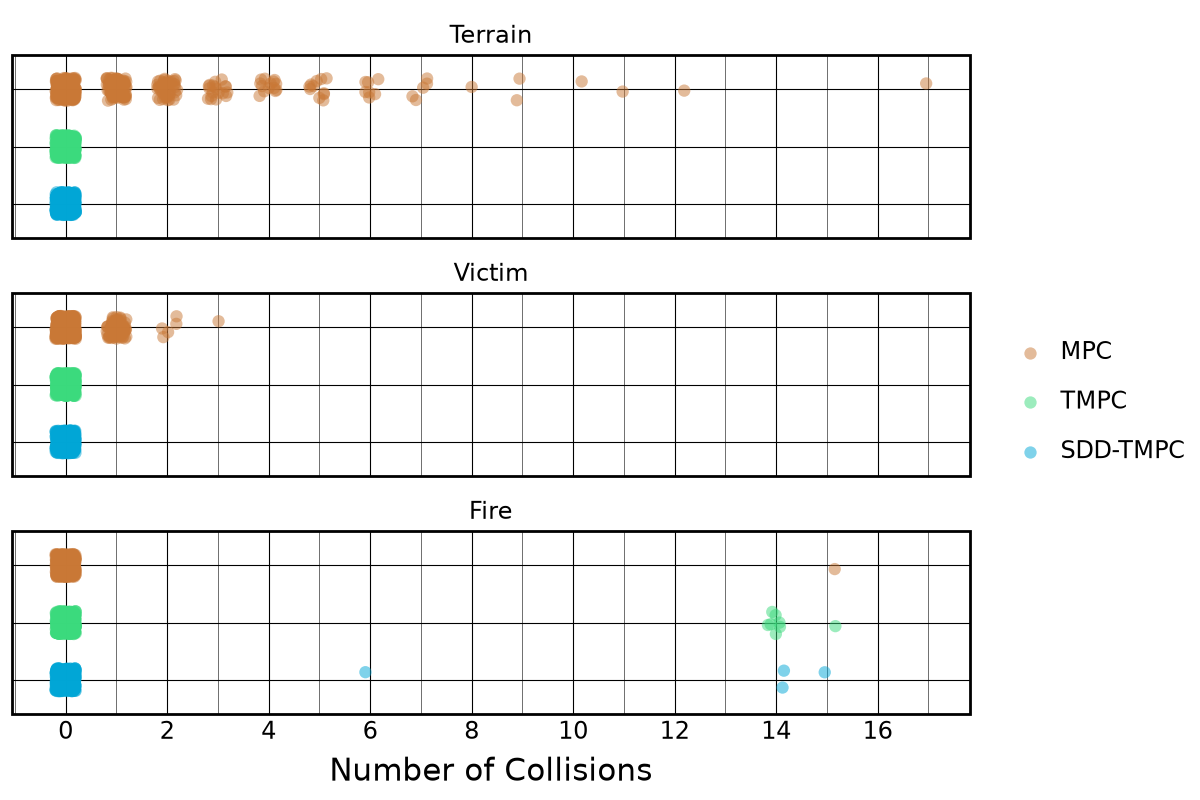

In [34]:
(
    ggplot(collisions, aes(x='type', y='collisions', fill='type'))
           + geom_jitter(width=0.2, height=0.2, alpha=0.5, size=2, colour='#00000000')
           + coord_flip()
           + facet_wrap('collision_type', nrow=3)
        #    + labs(x='', y='Number of Collisions', title='Collision Frequency by Agent and Collision Type', size='Number of Runs', fill='')
           + labs(x='', y='Number of Collisions', fill='')
           + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
           + scale_y_continuous(breaks=range(0,20,2))
           + scale_fill_manual(values=['#C97836', '#3BDA7D', '#01A6D6'])
           + scale_size_continuous(range=(1,15), guide=None)
           + theme_poster((6, 4))
           + theme(axis_text_y=element_blank())
) 

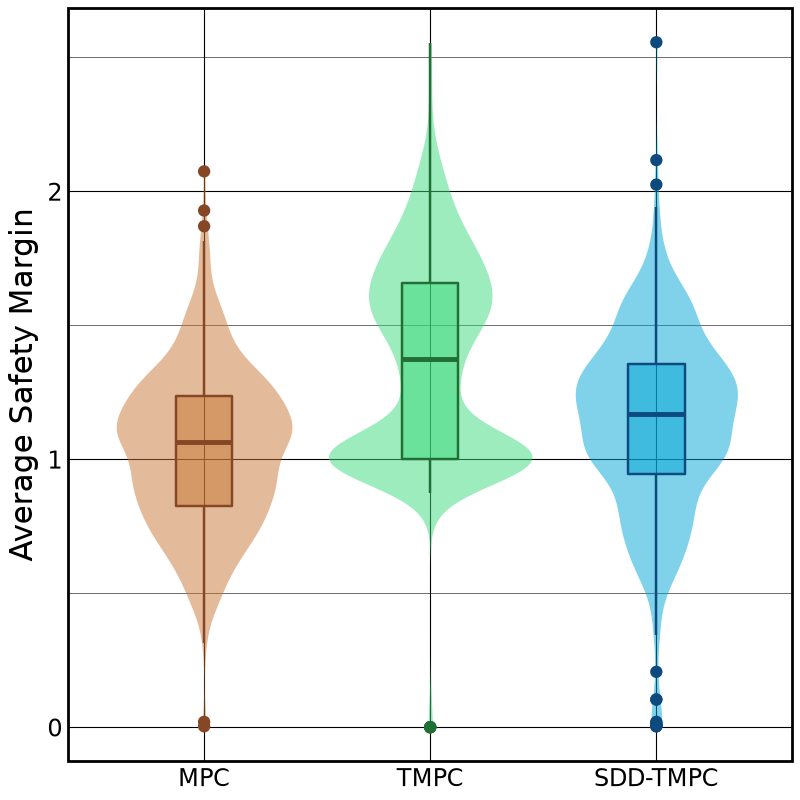

In [35]:
(
    ggplot(margins, aes(x='type', y='Average Safety Margin', colour='type', fill='type'))
           + geom_violin(colour=None)
           + geom_boxplot(width=0.25)
           + labs(x='', fill='')
           + scale_fill_manual(values=['#C9783680', '#3BDA7D80', '#01A6D680'], guide=None)
           + scale_colour_manual(values=["#864726", "#216F35", "#0E4A7E"], guide=None)
           + theme_poster((4, 4))
)

# Performance
### Data Handling

In [36]:
finished = data[data['outcome']=='SUCCESS']

runtimes = finished[['outcome', 'duration', 'type']]
runtimes.columns = ['Outcome', 'Duration', 'type']
print(runtimes.groupby('type').mean(numeric_only=True))

found = data[['victims_found', 'type']]
found.columns = ['Victims Found', 'type']

success = finished[['outcome', 'type']]
success = success.groupby('type').count().reset_index()
success['outcome'] /= mpc.shape[0]

flawless = finished[(finished['wall_collisions']==0) & (finished['victims_collisions']==0) & (finished['fire_collisions']==0)]
flawless = flawless[['outcome', 'type']]
flawless = flawless.groupby('type').count().reset_index()
flawless['outcome'] /= mpc.shape[0]

print(success)
print(flawless)

def McNemarIgnore(type_1: str, type_2: str):
    pos_pos = joint[(joint['outcome_'+type_1]=='SUCCESS') & (joint['outcome_'+type_2]=='SUCCESS')].shape[0]
    pos_neg = joint[(joint['outcome_'+type_1]=='SUCCESS') & (joint['outcome_'+type_2]=='TIMEOUT')].shape[0]
    neg_pos = joint[(joint['outcome_'+type_1]=='TIMEOUT') & (joint['outcome_'+type_2]=='SUCCESS')].shape[0]
    neg_neg = joint[(joint['outcome_'+type_1]=='TIMEOUT') & (joint['outcome_'+type_2]=='TIMEOUT')].shape[0]
    contingency = pd.DataFrame([[pos_pos, pos_neg], [neg_pos, neg_neg]])
    return mcnemar(contingency, exact=True)

def McNemarFail(type_1: str, type_2: str):
    pos_pos = joint[(joint['outcome_'+type_1]=='SUCCESS')
                    & (joint['outcome_'+type_2]=='SUCCESS')].shape[0]
    pos_neg = joint[(joint['outcome_'+type_1]=='SUCCESS') 
                    & ((joint['outcome_'+type_2]=='TIMEOUT') | (joint['wall_collisions_'+type_2]) | (joint['victims_collisions_'+type_2]) | (joint['fire_collisions_'+type_2]))].shape[0]
    neg_pos = joint[((joint['outcome_'+type_1]=='TIMEOUT') | (joint['wall_collisions_'+type_1]) | (joint['victims_collisions_'+type_1]) | (joint['fire_collisions_'+type_1])) 
                    & (joint['outcome_'+type_2]=='SUCCESS')].shape[0]
    neg_neg = joint[((joint['outcome_'+type_1]=='TIMEOUT') | (joint['wall_collisions_'+type_1]) | (joint['victims_collisions_'+type_1]) | (joint['fire_collisions_'+type_1])) 
                    &((joint['outcome_'+type_2]=='TIMEOUT') | (joint['wall_collisions_'+type_2]) | (joint['victims_collisions_'+type_2]) | (joint['fire_collisions_'+type_2]))].shape[0]
    contingency = pd.DataFrame([[pos_pos, pos_neg], [neg_pos, neg_neg]])
    return mcnemar(contingency, exact=True)

print(McNemarIgnore('mpc', 'tmpc'))
print(McNemarIgnore('mpc', 'sdd'))
print(McNemarIgnore('tmpc', 'sdd'))
print(McNemarFail('mpc', 'tmpc'))
print(McNemarFail('mpc', 'sdd'))
print(McNemarFail('tmpc', 'sdd'))


            Duration
type                
MPC       156.621399
TMPC      171.800000
SDD-TMPC  169.541667
       type  outcome
0       MPC    0.972
1      TMPC    0.350
2  SDD-TMPC    0.816
       type  outcome
0       MPC    0.502
1      TMPC    0.344
2  SDD-TMPC    0.812
pvalue      4.794036587204811e-94
statistic   0.0
pvalue      1.3400325923359048e-22
statistic   1.0
pvalue      2.554063727392286e-67
statistic   2.0
pvalue      1.0376464014457322e-36
statistic   73.0
pvalue      5.713732521329164e-09
statistic   81.0
pvalue      4.011435591279654e-65
statistic   4.0


In [37]:
mpc_collision_total = joint[(joint['wall_collisions_mpc']!=0) | (joint['victims_collisions_mpc']!=0) | (joint['fire_collisions_mpc']!=0)]
mpc_collision_tmpc_fail = mpc_collision_total[(mpc_collision_total['outcome_tmpc']=='TIMEOUT')]
tmpc_fail_total = joint[(joint['outcome_tmpc']=='TIMEOUT')]
mpc_collision_sdd_fail = mpc_collision_total[(mpc_collision_total['outcome_sdd']=='TIMEOUT')]
sdd_fail_total = joint[(joint['outcome_sdd']=='TIMEOUT')]
print(mpc_collision_total.shape[0]/joint.shape[0])
print(mpc_collision_tmpc_fail.shape[0]/ tmpc_fail_total.shape[0])
print(mpc_collision_sdd_fail.shape[0]/ sdd_fail_total.shape[0])

collision_timeout = pd.DataFrame(columns=['mpc_collision', 'tmpc_timeout', 'sdd_timeout'])
collision_timeout['mpc_collision'] = ((joint['wall_collisions_mpc']!=0) | (joint['victims_collisions_mpc']!=0) | (joint['fire_collisions_mpc']!=0)).astype(int)
collision_timeout['tmpc_timeout'] = (joint['outcome_tmpc']=='TIMEOUT').astype(int)
collision_timeout['sdd_timeout'] = (joint['outcome_sdd']=='TIMEOUT').astype(int)
model = logit('mpc_collision ~ tmpc_timeout + sdd_timeout', data=collision_timeout).fit()
print(model.summary())
print(np.exp(model.params))
print(np.exp(model.conf_int()))

# Unsuccessful runs ignored
print('\nBOTH SUCCESSFUL')

joint_finished = joint[(joint['outcome_mpc']=='SUCCESS') & (joint['outcome_tmpc']=='SUCCESS')]
mpc_tmpc = joint_finished[['duration_mpc', 'duration_tmpc']]
joint_finished = joint[(joint['outcome_mpc']=='SUCCESS') & (joint['outcome_sdd']=='SUCCESS')]
mpc_sdd = joint_finished[['duration_mpc', 'duration_sdd']]
joint_finished = joint[(joint['outcome_tmpc']=='SUCCESS') & (joint['outcome_sdd']=='SUCCESS')]
tmpc_sdd = joint_finished[['duration_tmpc', 'duration_sdd']]
print((tmpc_sdd['duration_tmpc']-tmpc_sdd['duration_sdd']).mean())

s_both_1, p_both_1 = wilcoxon(mpc_tmpc['duration_mpc'], mpc_tmpc['duration_tmpc'])
s_both_2, p_both_2 = wilcoxon(mpc_sdd['duration_mpc'], mpc_sdd['duration_sdd'])
s_both_3, p_both_3 = wilcoxon(tmpc_sdd['duration_tmpc'], tmpc_sdd['duration_sdd'])
reject, p_both_joint, _, _ = multipletests([p_both_1, p_both_2, p_both_3], method='bonferroni')
print(reject, p_both_joint)

p_equiv, low, upp = ttost_paired(mpc_sdd['duration_mpc'], mpc_sdd['duration_sdd'], -10, 10)
print(p_equiv, low, upp)

stats_obj = DescrStatsW(mpc_sdd['duration_mpc'] - mpc_sdd['duration_sdd'])
ci_low, ci_upp = stats_obj.tconfint_mean(alpha=0.10)
print(ci_low, ci_upp)

# Unsuccessful runs included
print('\nALL RUNS')
print(wilcoxon(mpc['duration'], tmpc['duration']))
print(wilcoxon(mpc['duration'], sdd['duration']))
print(wilcoxon(tmpc['duration'], sdd['duration']))

0.48
0.5138461538461538
0.7282608695652174
Optimization terminated successfully.
         Current function value: 0.663654
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          mpc_collision   No. Observations:                  500
Model:                          Logit   Df Residuals:                      497
Method:                           MLE   Df Model:                            2
Date:                Sat, 20 Jun 2026   Pseudo R-squ.:                 0.04144
Time:                        17:13:28   Log-Likelihood:                -331.83
converged:                       True   LL-Null:                       -346.17
Covariance Type:            nonrobust   LLR p-value:                 5.879e-07
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.3486      0.154     -2.269      0.023     

In [38]:
long = data[['seed', 'type', 'duration']]
long['duration'] = long['duration'].apply(lambda x: np.nan if x==300 else x)
long = long.dropna()
long['log_duration'] = np.log(long['duration'])
model = mixedlm('log_duration ~ type', long, groups=long['seed'])
print(model.fit().summary())

           Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: log_duration
No. Observations:  1069    Method:             REML        
No. Groups:        487     Scale:              0.0414      
Min. group size:   1       Log-Likelihood:     -129.6191   
Max. group size:   3       Converged:          Yes         
Mean group size:   2.2                                     
-----------------------------------------------------------
                 Coef. Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept        5.011    0.014 366.673 0.000  4.985  5.038
type[T.TMPC]     0.133    0.020   6.798 0.000  0.094  0.171
type[T.SDD-TMPC] 0.081    0.014   5.759 0.000  0.053  0.108
Group Var        0.049    0.029                            



### Plotting

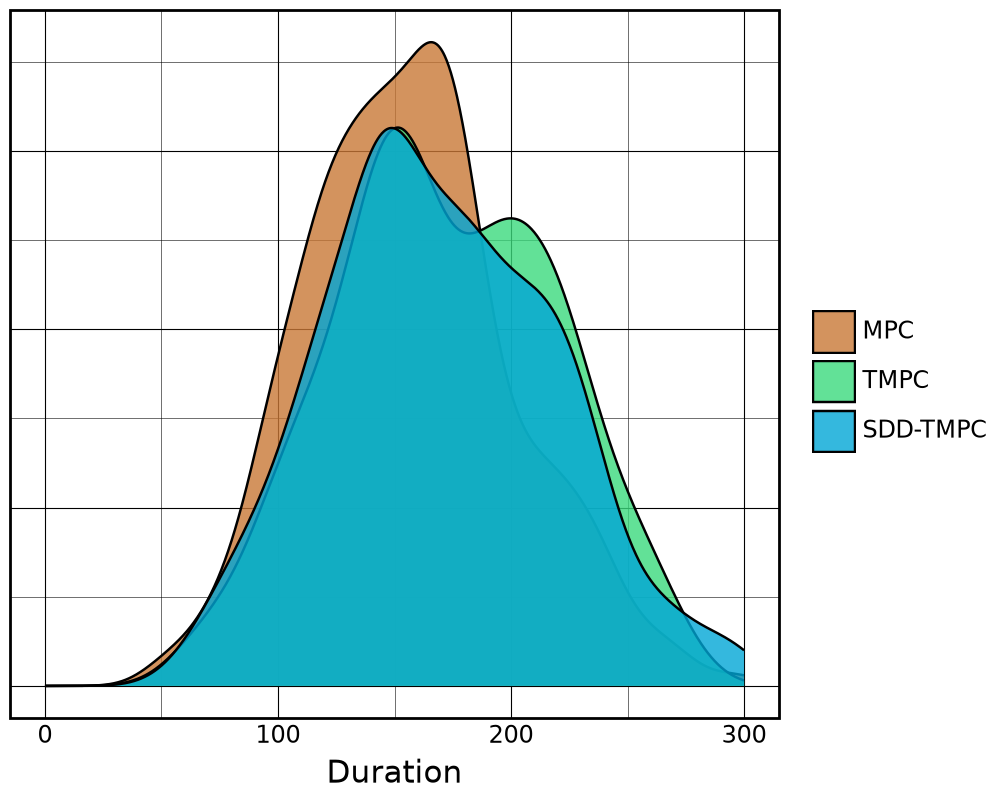

In [39]:
(
    ggplot(runtimes, aes(x='Duration', fill='type'))
           + geom_density(kernel='gaussian', position='identity', alpha=0.8)
        #    + labs(x='Duration', y='', title='Mission Durations by Agent Type', subtitle='(unsuccessful runs excluded)', fill='')
           + labs(x='Duration', y='', fill='')
           + scale_fill_manual(values=['#C97836', '#3BDA7D', '#01A6D6'])
           + scale_x_continuous(limits=(0, 300))
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'),
                   plot_subtitle=element_text(ha='center'),
                   axis_text_y=element_blank(),
                   axis_ticks_y=element_blank()
           )
)

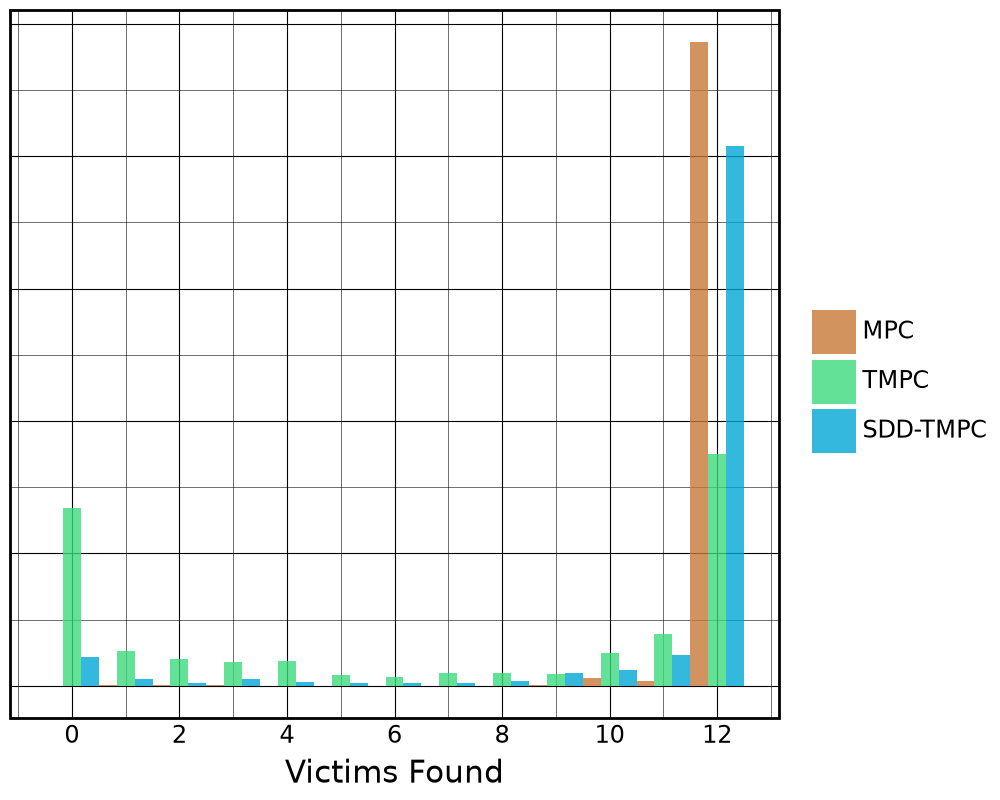

In [51]:
(
    ggplot(found, aes(x='Victims Found', fill='type'))
           + geom_histogram(bins=13, position='dodge', alpha=0.8)
           + labs(x='Victims Found', y='', fill='')
           + scale_fill_manual(values=['#C97836', '#3BDA7D', '#01A6D6'])
           + scale_x_continuous(breaks=range(0, 14, 2))
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'),
                   plot_subtitle=element_text(ha='center'),
                   axis_text_y=element_blank(),
                   axis_ticks_y=element_blank()
           )
)

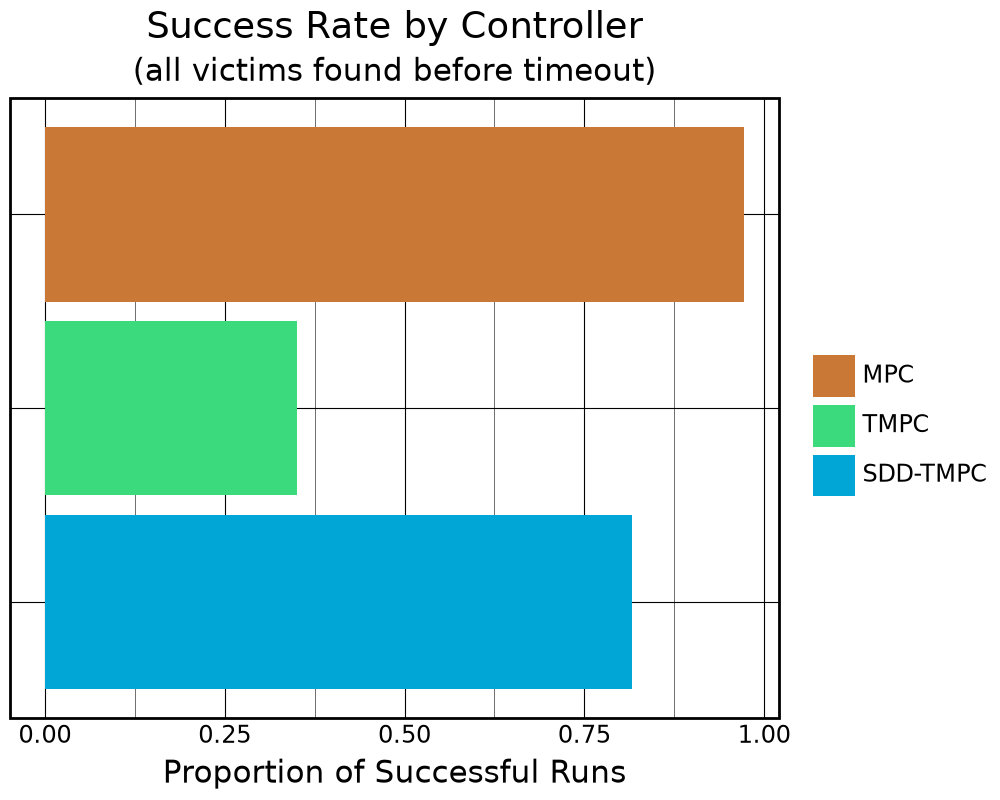

In [41]:
(
    ggplot(success, aes(x='type', y='outcome', fill='type'))
           + geom_col(colour='#00000000')
           + coord_flip()
           + labs(x='', y='Proportion of Successful Runs', title='Success Rate by Controller', subtitle='(all victims found before timeout)', fill='')
           + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
           + scale_fill_manual(values=['#C97836', '#3BDA7D', '#01A6D6'])
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'), plot_subtitle=element_text(ha='center'), axis_text_y=element_blank())
)

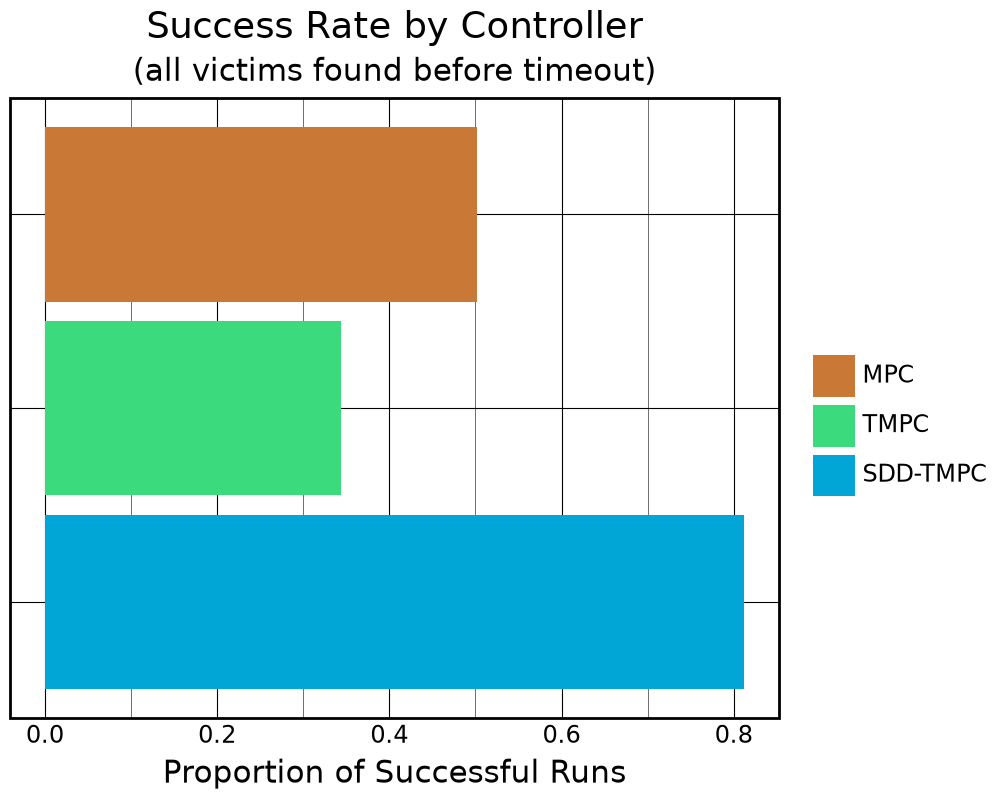

In [42]:
(
    ggplot(flawless, aes(x='type', y='outcome', fill='type'))
           + geom_col(colour='#00000000')
           + coord_flip()
           + labs(x='', y='Proportion of Successful Runs', title='Success Rate by Controller', subtitle='(all victims found before timeout)', fill='')
           + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
           + scale_fill_manual(values=['#C97836', '#3BDA7D', '#01A6D6'])
           + theme_poster((5, 4))
           + theme(plot_title=element_text(ha='center'), plot_subtitle=element_text(ha='center'), axis_text_y=element_blank())
)